In [1]:
import sys

# this kernel's numpy (2.1.2) + uproot (5.1.2) combo raises OverflowError reading JetClass
# .root files - prepend the deps folder with compatible versions before anything imports numpy
deps_path = "/home/users/w/wozniak/.local/ntp4jets-deps"
if deps_path not in sys.path:
    sys.path.insert(0, deps_path)

import pyrootutils

pyrootutils.setup_root(__file__ if "__file__" in dir() else ".", indicator=".project-root", pythonpath=True)

import hydra
import numpy as np
import torch
import matplotlib.pyplot as plt
from omegaconf import OmegaConf

from gabbro.models.backbone_multihead import BackboneMultiHeadLightning

from hydra import compose, initialize_config_dir
from hydra.core.global_hydra import GlobalHydra

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device


device(type='cuda')

# load aoj dataset

In [2]:
GlobalHydra.instance().clear()
with initialize_config_dir(
    config_dir="/home/users/w/wozniak/dev/enhancing-ntp4jets/configs", version_base=None
):
    cfg_aoj = compose(
        config_name="train",
        overrides=[
            "experiment=example_experiment_backbone_and_head_allfeat_ntp_classifier_head",
            "feature_dict=feature_dict_all_without_cuts",
        ],
    )

AOJ_FILE = "/srv/beegfs/scratch/groups/rodem/lumea/datasets/aspenJets/RunG_batch0.h5"

# switch off the tokenized-parquet codepath and jetclass-only extras, point at the AOJ file
cfg_aoj.data.dataset_kwargs_common.dataset_type = "aoj"
cfg_aoj.data.dataset_kwargs_common.token_id_cfg = None
cfg_aoj.data.dataset_kwargs_common.feature_dict_labels_particles = None
cfg_aoj.data.dataset_kwargs_common.feature_dict_jet = None
cfg_aoj.data.dataset_kwargs_common.labels_to_load = ["label_QCD"]

cfg_aoj.data.data_dir = "/srv/beegfs/scratch/groups/rodem/lumea/datasets/aspenJets"
# `setup(stage="fit")` also builds the val dataset, so point that at the same single file too
cfg_aoj.data.dataset_kwargs_train.files_dict = {"QCD": [AOJ_FILE]}
cfg_aoj.data.dataset_kwargs_train.max_n_files_per_type = 1
cfg_aoj.data.dataset_kwargs_val.files_dict = {"QCD": [AOJ_FILE]}
cfg_aoj.data.dataset_kwargs_val.max_n_files_per_type = 1

# disable all shuffling so batch order is just the file's on-disk order, identical every run
for split in ["train", "val", "test"]:
    cfg_aoj.data[f"dataset_kwargs_{split}"].shuffle_files = False
    cfg_aoj.data[f"dataset_kwargs_{split}"].shuffle_data = False

print(OmegaConf.to_yaml(cfg_aoj.data.dataset_kwargs_common.feature_dict, resolve=True))

part_pt:
  multiply_by: 1
  subtract_by: 1.8
  func: signed_log
  inv_func: signed_exp
part_etarel:
  multiply_by: 3
part_phirel:
  multiply_by: 3
part_mass:
  clip_min_input_space: 0
part_charge: null
part_isChargedHadron: null
part_isNeutralHadron: null
part_isPhoton: null
part_isElectron: null
part_isMuon: null
part_d0val:
  func: signed_log
  inv_func: signed_exp
part_dzval:
  func: signed_log
  inv_func: signed_exp
part_d0err: null
part_dzerr: null



In [3]:
datamodule_aoj = hydra.utils.instantiate(cfg_aoj.data)
# AOJ has no separate train/val/test split - just read the file(s) directly
datamodule_aoj.setup(stage="fit")

train_dataloader_aoj = datamodule_aoj.train_dataloader()

Parameter seed is present in both dataset_kwargs_common (value=92734) and dataset_kwargs_train(value=42). Using the value from dataset_kwargs_train.
Parameter seed is present in both dataset_kwargs_common (value=92734) and dataset_kwargs_val(value=1). Using the value from dataset_kwargs_val.
Parameter seed_shuffle_data is present in both dataset_kwargs_common (value=92734) and dataset_kwargs_val(value=1). Using the value from dataset_kwargs_val.
Parameter seed_shuffle_data is present in both dataset_kwargs_common (value=92734) and dataset_kwargs_test(value=42). Using the value from dataset_kwargs_test.
Parameter random_seed_for_per_file_shuffling is present in both dataset_kwargs_common (value=92734) and dataset_kwargs_val(value=None). Using the value from dataset_kwargs_val.
random_seed_for_per_file_shuffling is only used if load_only_once is True.
shuffle_files is False. This means that the files list will not be shuffled.
shuffle_files is False. Will not shuffle files and continue w

# load ntp model

In [4]:
CKPT_PATH = (
    "/home/users/w/wozniak/dev/enhancing-ntp4jets/trained/omnijet-backbone-multihead-allfeat-ntp-classifier-head/runs/2026-09-14_17-32-09_gpu047_NeonatalSulfur/checkpoints/last.ckpt"
)

# Load the *resolved* config that was actually used to train this checkpoint (saved next to the
# run's checkpoints directory), instead of re-composing from the current experiment yaml. This
# matters because the experiment yaml can change over time (e.g. the `feature_dict` override in
# `example_experiment_backbone_and_head.yaml` has since been changed to the extended/all-features
# set), while this specific checkpoint was trained with a different feature_dict
# (`feature_dict_kin_massless_without_cuts.yaml`). Using the checkpoint's own resolved config
# guarantees the preprocessing/feature_dict/tokenization match what the model was actually trained on.
from pathlib import Path

resolved_cfg_path = Path(CKPT_PATH).parent.parent / "config_resolved.yaml"
cfg = OmegaConf.load(resolved_cfg_path)

print(OmegaConf.to_yaml(cfg.data.dataset_kwargs_common.feature_dict))

part_pt:
  multiply_by: 1
  subtract_by: 1.8
  func: signed_log
  inv_func: signed_exp
part_etarel:
  multiply_by: 3
part_phirel:
  multiply_by: 3
part_mass:
  clip_min_input_space: 0
part_charge: null
part_isChargedHadron: null
part_isNeutralHadron: null
part_isPhoton: null
part_isElectron: null
part_isMuon: null
part_d0val:
  func: signed_log
  inv_func: signed_exp
part_dzval:
  func: signed_log
  inv_func: signed_exp
part_d0err: null
part_dzerr: null



In [5]:
model_ntp = BackboneMultiHeadLightning.load_from_checkpoint(CKPT_PATH, map_location=device)
model_ntp = model_ntp.to(device)
model_ntp.eval()

print(f"head_mpm is active: {model_ntp.head_mpm is not None}")
print(f"head_gen is active: {model_ntp.head_gen is not None}")
print(f"head_class is active: {model_ntp.head_class is not None}")

NOT applying causal mask in the attention blocks. If you are using this model for an autoregressive generative task, this is probably not what you want.


head_mpm is active: False
head_gen is active: False
head_class is active: True


In [6]:
ntp_backbone_out_list = []
ntp_part_mask_list = []
ntp_logits_gen_list = []
ntp_logits_mpm_list = []
ntp_logits_class_list = []

with torch.no_grad():
    for i, batch in enumerate(train_dataloader_aoj):
        if i >= 10:
            break

        part_features = batch["part_features"].to(device)
        part_mask = batch["part_mask"].to(device).int()

        # AOJ isn't tokenized, so unlike JetClass there's no reserved all-zero slot at
        # position 0 - prepend the learned start token as an extra particle instead.
        # Truncate to leave room for it, since the model's max_sequence_len (and the
        # size of masked_feature_vector) doesn't allow for a longer sequence.
        if model_ntp.hparams.start_token_type in ["trainable", "zero_pad"]:
            batch_size = part_features.shape[0]
            part_features = part_features[:, : cfg.model.backbone_cfg.max_sequence_len - 1]
            part_mask = part_mask[:, : cfg.model.backbone_cfg.max_sequence_len - 1]
            start_token = model_ntp.start_token_continuous.unsqueeze(0).repeat(batch_size, 1, 1)
            part_features = torch.cat([start_token, part_features], dim=1)
            start_mask = torch.ones(batch_size, 1, dtype=part_mask.dtype, device=device)
            part_mask = torch.cat([start_mask, part_mask], dim=1)

        # `model.forward()` only returns head logits, not the backbone's last-layer
        # representation - call the backbone module itself to get that
        backbone_out = model_ntp.backbone(part_features, mask=part_mask)
        ntp_backbone_out_list.append(backbone_out.cpu())
        ntp_part_mask_list.append(part_mask.cpu())

        logits_gen, logits_mpm, logits_class = model_ntp(
            part_features, valid_particle_mask=part_mask
        )

        if logits_gen is not None:
            ntp_logits_gen_list.append(logits_gen.cpu())
        if logits_mpm is not None:
            ntp_logits_mpm_list.append(logits_mpm.cpu())
        if logits_class is not None:
            ntp_logits_class_list.append(logits_class.cpu())

print(f"Ran inference on {len(ntp_logits_class_list)} batches.")

You are clipping the values of the feature 'part_mass' in input space with clip_min_input_space = 0 and clip_max_input_space = None. Make sure this is intended. THIS IS NOT INVERTIBLE.
shuffle_files is False. Will not shuffle files and continue with the previous order.


Ran inference on 10 batches.


## load mpm model

## 

In [7]:
CKPT_PATH = (
    "/home/users/w/wozniak/dev/enhancing-ntp4jets/trained/omnijet-backbone-multihead-allfeat-mpm-classifier-head/runs/2026-09-14_17-32-09_gpu024_TaxableSpecialism/checkpoints/last.ckpt"
)

# Load the *resolved* config that was actually used to train this checkpoint (saved next to the
# run's checkpoints directory), instead of re-composing from the current experiment yaml. This
# matters because the experiment yaml can change over time (e.g. the `feature_dict` override in
# `example_experiment_backbone_and_head.yaml` has since been changed to the extended/all-features
# set), while this specific checkpoint was trained with a different feature_dict
# (`feature_dict_kin_massless_without_cuts.yaml`). Using the checkpoint's own resolved config
# guarantees the preprocessing/feature_dict/tokenization match what the model was actually trained on.
from pathlib import Path

resolved_cfg_path = Path(CKPT_PATH).parent.parent / "config_resolved.yaml"
cfg = OmegaConf.load(resolved_cfg_path)

print(OmegaConf.to_yaml(cfg.data.dataset_kwargs_common.feature_dict))

part_pt:
  multiply_by: 1
  subtract_by: 1.8
  func: signed_log
  inv_func: signed_exp
part_etarel:
  multiply_by: 3
part_phirel:
  multiply_by: 3
part_mass:
  clip_min_input_space: 0
part_charge: null
part_isChargedHadron: null
part_isNeutralHadron: null
part_isPhoton: null
part_isElectron: null
part_isMuon: null
part_d0val:
  func: signed_log
  inv_func: signed_exp
part_dzval:
  func: signed_log
  inv_func: signed_exp
part_d0err: null
part_dzerr: null



In [8]:
model_mpm = BackboneMultiHeadLightning.load_from_checkpoint(CKPT_PATH, map_location=device)
model_mpm = model_mpm.to(device)
model_mpm.eval()

print(f"head_mpm is active: {model_mpm.head_mpm is not None}")
print(f"head_gen is active: {model_mpm.head_gen is not None}")
print(f"head_class is active: {model_mpm.head_class is not None}")

NOT applying causal mask in the attention blocks. If you are using this model for an autoregressive generative task, this is probably not what you want.


head_mpm is active: False
head_gen is active: False
head_class is active: True


In [9]:
mpm_backbone_out_list = []
mpm_part_mask_list = []
mpm_logits_gen_list = []
mpm_logits_mpm_list = []
mpm_logits_class_list = []

with torch.no_grad():
    for i, batch in enumerate(train_dataloader_aoj):
        if i >= 10:
            break

        part_features = batch["part_features"].to(device)
        part_mask = batch["part_mask"].to(device).int()

        # AOJ isn't tokenized, so unlike JetClass there's no reserved all-zero slot at
        # position 0 - prepend the learned start token as an extra particle instead.
        # Truncate to leave room for it, since the model's max_sequence_len (and the
        # size of masked_feature_vector) doesn't allow for a longer sequence.
        if model_mpm.hparams.start_token_type in ["trainable", "zero_pad"]:
            batch_size = part_features.shape[0]
            part_features = part_features[:, : cfg.model.backbone_cfg.max_sequence_len - 1]
            part_mask = part_mask[:, : cfg.model.backbone_cfg.max_sequence_len - 1]
            start_token = model_mpm.start_token_continuous.unsqueeze(0).repeat(batch_size, 1, 1)
            part_features = torch.cat([start_token, part_features], dim=1)
            start_mask = torch.ones(batch_size, 1, dtype=part_mask.dtype, device=device)
            part_mask = torch.cat([start_mask, part_mask], dim=1)

        # `model.forward()` only returns head logits, not the backbone's last-layer
        # representation - call the backbone module itself to get that
        mpm_backbone_out = model_mpm.backbone(part_features, mask=part_mask)
        mpm_backbone_out_list.append(mpm_backbone_out.cpu())
        mpm_part_mask_list.append(part_mask.cpu())

        logits_gen, logits_mpm, logits_class = model_mpm(
            part_features, valid_particle_mask=part_mask
        )

        if logits_gen is not None:
            mpm_logits_gen_list.append(logits_gen.cpu())
        if logits_mpm is not None:
            mpm_logits_mpm_list.append(logits_mpm.cpu())
        if logits_class is not None:
            mpm_logits_class_list.append(logits_class.cpu())
print(f"Ran inference on {len(mpm_logits_class_list)} batches.")

You are clipping the values of the feature 'part_mass' in input space with clip_min_input_space = 0 and clip_max_input_space = None. Make sure this is intended. THIS IS NOT INVERTIBLE.
shuffle_files is False. Will not shuffle files and continue with the previous order.


Ran inference on 10 batches.


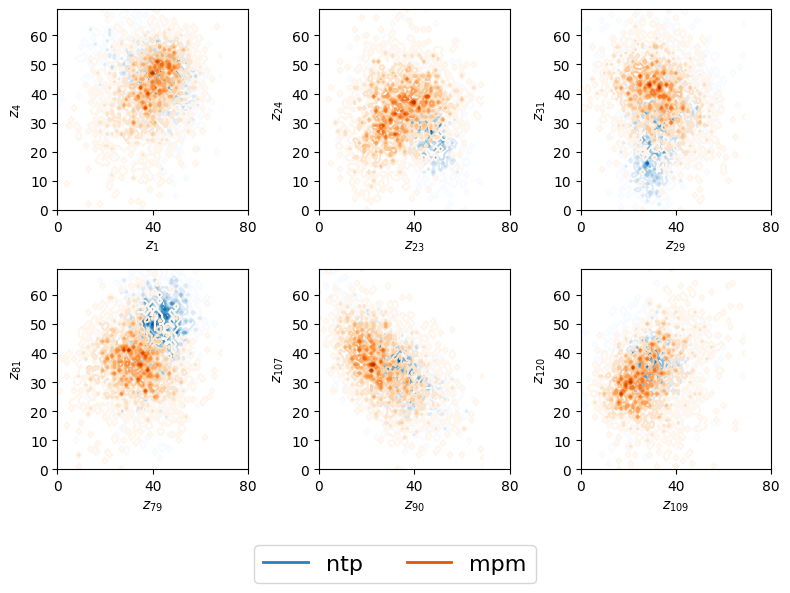

writing figure to analysis/aoj_inference/latent_space_2D_hist.png
Saved plot to analysis/aoj_inference


In [10]:
import os

from gabbro.utils.plotting_utils import plot_latent_space_2D_for_two_samples
import importlib

import gabbro.utils.plotting_utils as plotting_utils

importlib.reload(plotting_utils)


def mean_pool_backbone_out(backbone_out_list, mask_list):
    """Mean-pool per-particle backbone output over valid (non-padded) particles per jet."""
    reps = []
    for backbone_out, mask in zip(backbone_out_list, mask_list):
        mask = mask.float().unsqueeze(-1)
        summed = (backbone_out * mask).sum(dim=1)
        counts = mask.sum(dim=1).clamp(min=1)
        reps.append(summed / counts)
    return torch.cat(reps).numpy()


latent_ntp = mean_pool_backbone_out(ntp_backbone_out_list, ntp_part_mask_list)
latent_mpm = mean_pool_backbone_out(mpm_backbone_out_list, mpm_part_mask_list)

output_dir = "analysis/aoj_inference"
os.makedirs(output_dir, exist_ok=True)

# ntp = background, mpm = signal
plot_latent_space_2D_for_two_samples(
    latent_bg=latent_ntp,
    latent_sig=latent_mpm,
    n_dims=12,
    title_suffix="ntp vs mpm representations",
    filename_suffix="ntp_vs_mpm_backbone",
    fig_dir=output_dir,
    show_plot=True,
    legend_outside=True,
    fig_size=(8, 6),
    sample_names=["ntp", "mpm"]
)
print(f"Saved plot to {output_dir}")

/home/users/w/wozniak/.local/ntp4jets-umap/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/users/w/wozniak/.local/ntp4jets-umap/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


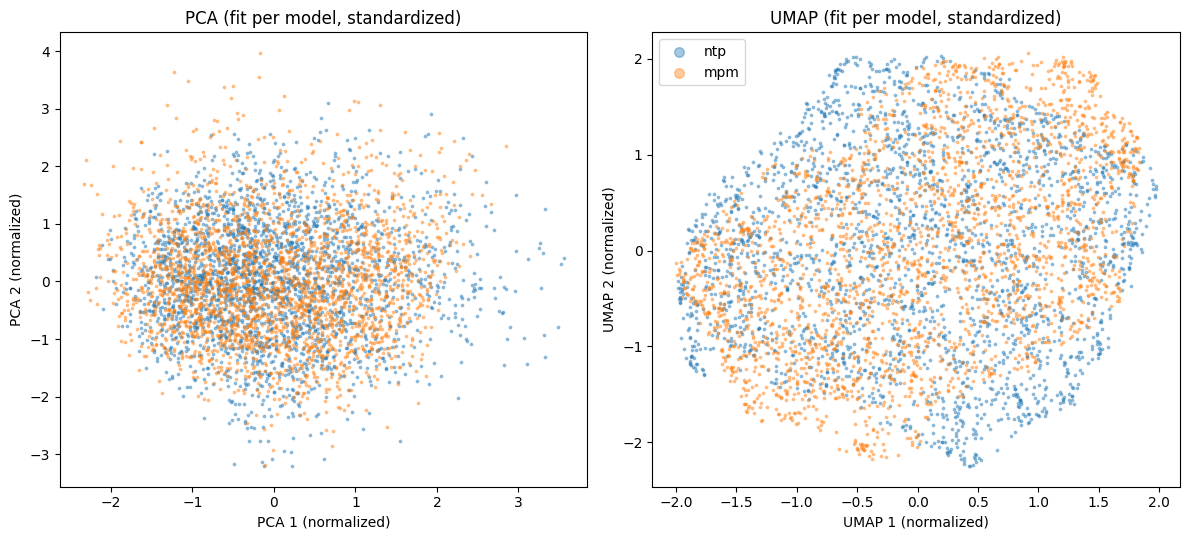

In [11]:
import sys

# umap-learn lives in its own folder to avoid touching ntp4jets-deps
umap_path = "/home/users/w/wozniak/.local/ntp4jets-umap"
if umap_path not in sys.path:
    sys.path.append(umap_path)

import matplotlib.pyplot as plt
import umap
from sklearn.decomposition import PCA


def standardize(emb):
    """Zero mean / unit std per axis, so embeddings of different models share a scale."""
    return (emb - emb.mean(axis=0)) / emb.std(axis=0)


# fit PCA/UMAP separately per model on all dims, then normalize each embedding on its own
embeddings = {}
for name, latent in {"ntp": latent_ntp, "mpm": latent_mpm}.items():
    embeddings[name] = {
        "PCA": standardize(PCA(n_components=2).fit_transform(latent)),
        "UMAP": standardize(umap.UMAP(n_components=2, random_state=0).fit_transform(latent)),
    }

# same colors as the pair plot: ntp = blue, mpm = orange
colors = {"ntp": "tab:blue", "mpm": "tab:orange"}
fig, axs = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, method in zip(axs, ["PCA", "UMAP"]):
    for name, emb in embeddings.items():
        ax.scatter(emb[method][:, 0], emb[method][:, 1], s=3, alpha=0.4, color=colors[name], label=name)
    ax.set_title(f"{method} (fit per model, standardized)")
    ax.set_xlabel(f"{method} 1 (normalized)")
    ax.set_ylabel(f"{method} 2 (normalized)")
axs[1].legend(markerscale=4)

fig.tight_layout()
fig.savefig(os.path.join(output_dir, "ntp_vs_mpm_backbone_pca_umap.png"), bbox_inches="tight")
plt.show()


# jet pooled embeddings

In [12]:
import h5py
from matplotlib.colors import LogNorm
from matplotlib.ticker import ScalarFormatter
from sklearn.manifold import TSNE


# fit PCA/UMAP separately per model on all dims, same log color scale (jet pt) for both
latents_pooled = {"ntp": latent_ntp, "mpm": latent_mpm}

# fit PCA once per model on the full (n_particles x latent_dim) vector of each jet
embeddings_pooled = {
    "PCA": {name: PCA(n_components=2).fit_transform(latent) for name, latent in latents_pooled.items()},
    "UMAP": {name: umap.UMAP(n_components=2, random_state=0).fit_transform(latent) for name, latent in latents_pooled.items()},
    "TSNE": {name: TSNE(n_components=2, random_state=0).fit_transform(latent) for name, latent in latents_pooled.items()},
}

# get jet kinematics and multiplicity
# jet pt isn't part of the batches (feature_dict_jet=None), but the dataloader is unshuffled, so
# the first n jets of the h5 file are exactly the jets that were passed through the models
n_jets = len(latent_ntp)
    
with h5py.File(AOJ_FILE, "r") as f:
    jet_pt = f["jet_kinematics"][:n_jets, 0]
    jet_eta, jet_phi = f["jet_kinematics"][:n_jets, 1], f["jet_kinematics"][:n_jets, 2]
assert len(jet_pt) == len(latent_mpm) == n_jets

multiplicity = torch.cat([m.sum(dim=1) for m in ntp_part_mask_list]).numpy() - 1

colorings = {
    "jet pt [GeV] (log scale)": (jet_pt, dict(cmap="viridis", norm=LogNorm(*np.percentile(jet_pt, [1, 99]))), "jetpt"),
    "jet eta": (jet_eta, dict(cmap="coolwarm", vmin=-2.5, vmax=2.5), "jeteta"),
    "jet phi": (jet_phi, dict(cmap="coolwarm", vmin=-np.pi, vmax=np.pi), "jetphi"),
    "particle multiplicity": (multiplicity, dict(cmap="viridis"), "multiplicity"),
}


/home/users/w/wozniak/.local/ntp4jets-umap/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/users/w/wozniak/.local/ntp4jets-umap/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


## PCA jet pooled

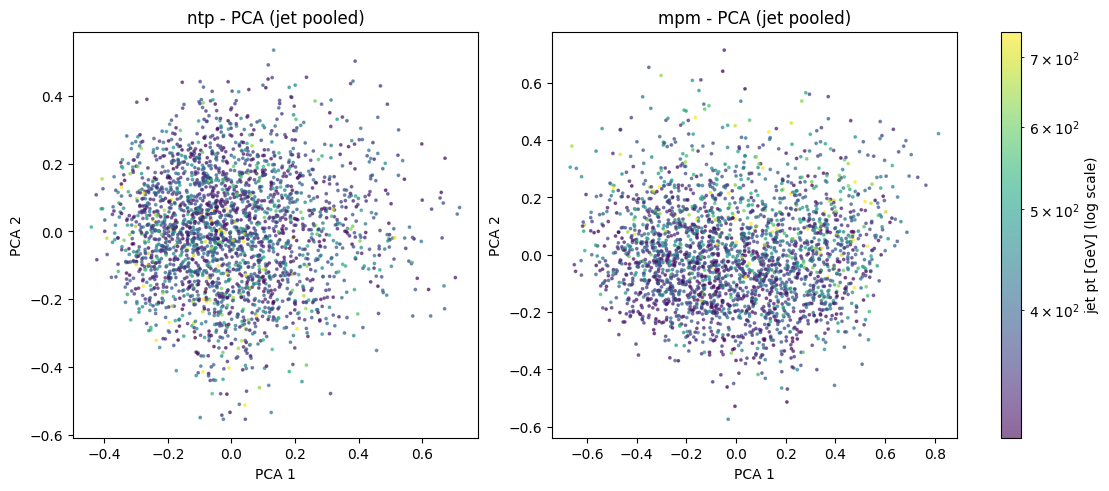

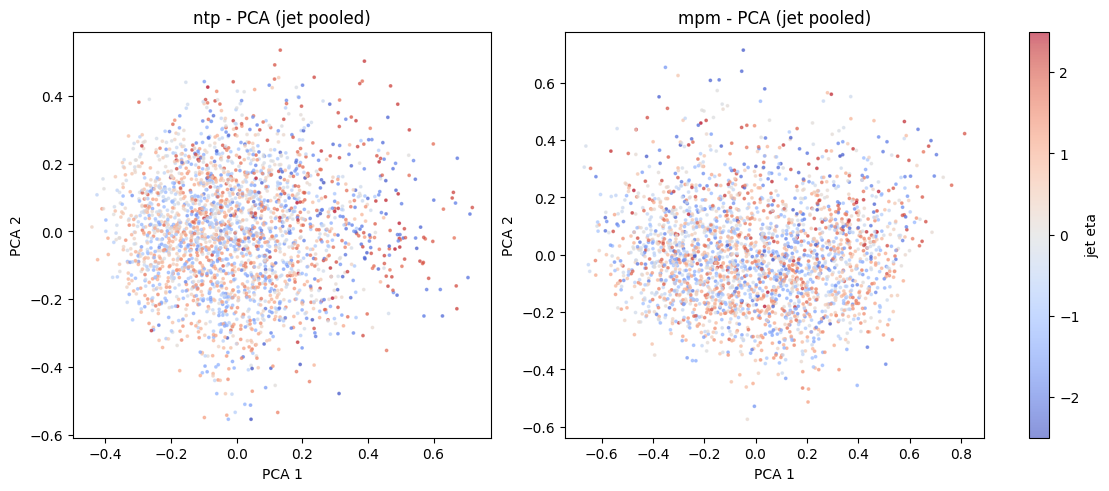

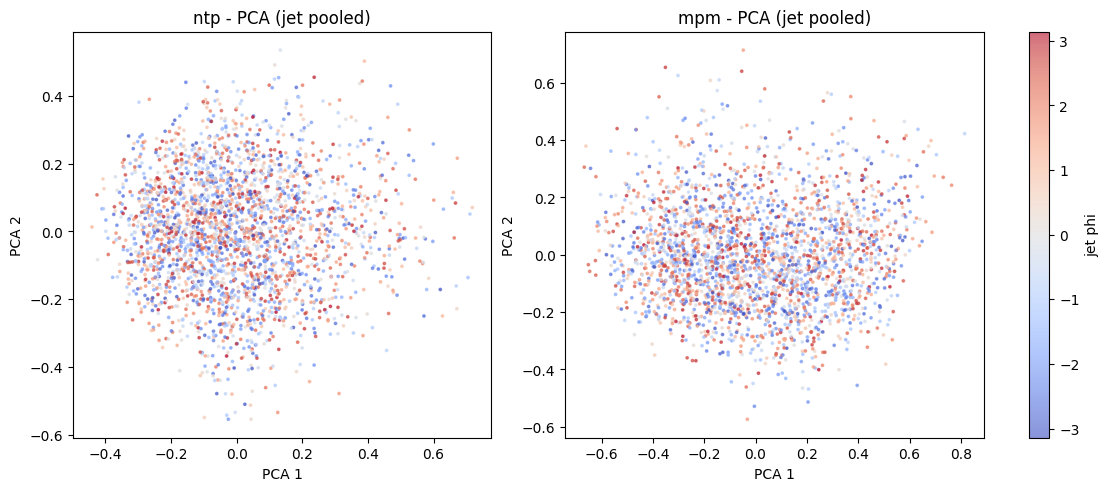

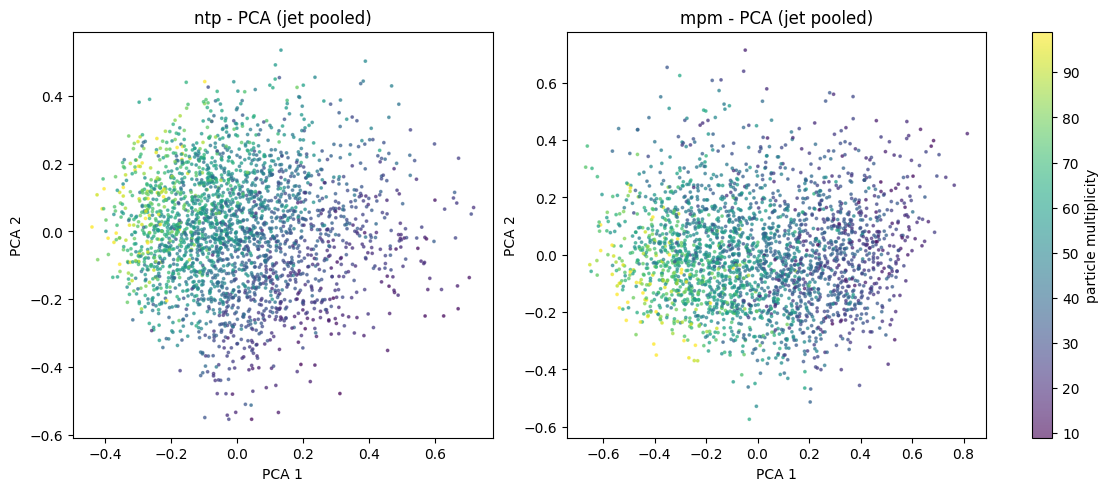

In [13]:

embeddings = embeddings_pooled["PCA"]
for label, (values, cmap_kwargs, file_tag) in colorings.items():
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.8), layout="constrained")
    for ax, (name, emb) in zip(axs, embeddings.items()):
        sc = ax.scatter(emb[:, 0], emb[:, 1], c=values, s=3, alpha=0.6, **cmap_kwargs)
        ax.set_title(f"{name} - PCA (jet pooled)")
        ax.set_xlabel("PCA 1")
        ax.set_ylabel("PCA 2")
    fig.colorbar(sc, ax=axs, label=label)
    fig.savefig(
        os.path.join(output_dir, f"ntp_vs_mpm_backbone_pca_jet_pooled_{file_tag}.png"), bbox_inches="tight"
    )
    plt.show()


## umap - jet pooled

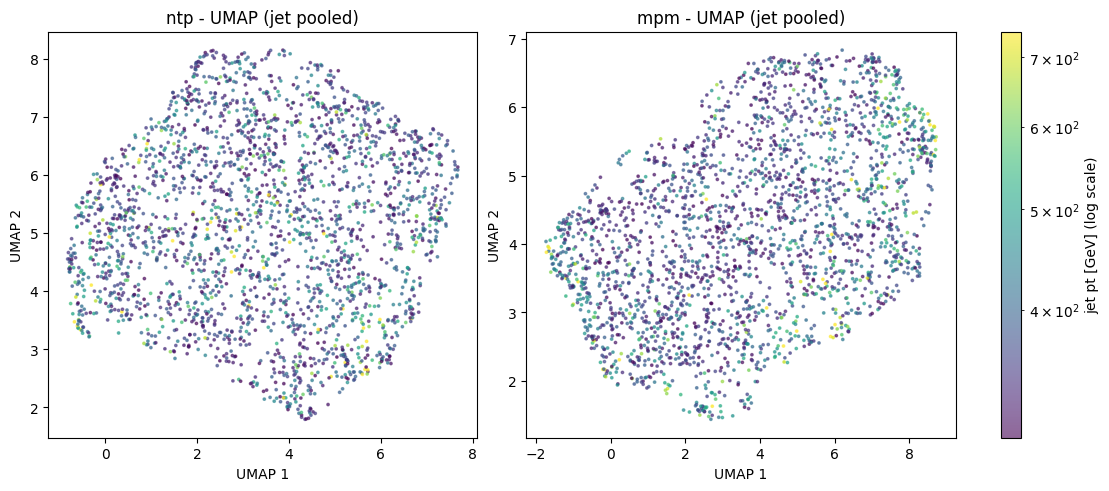

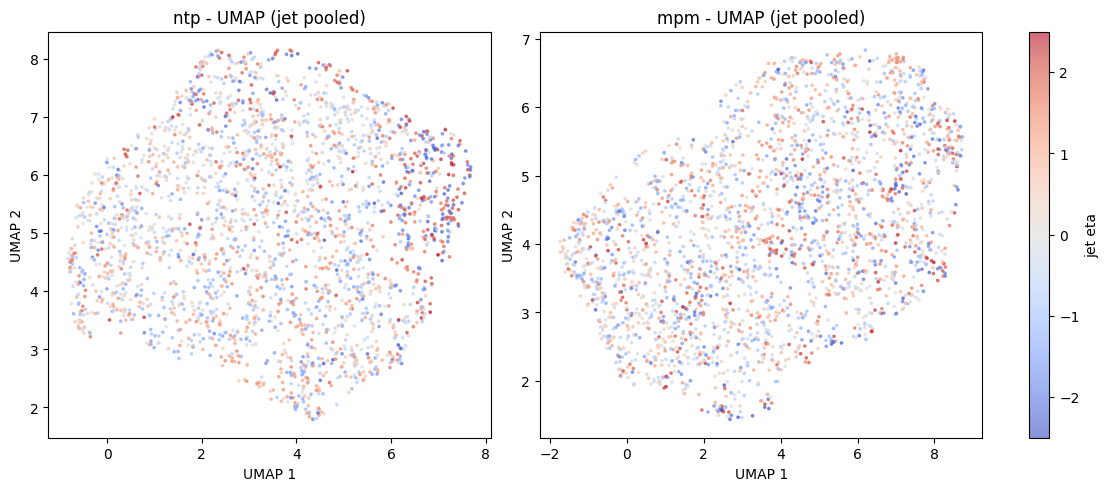

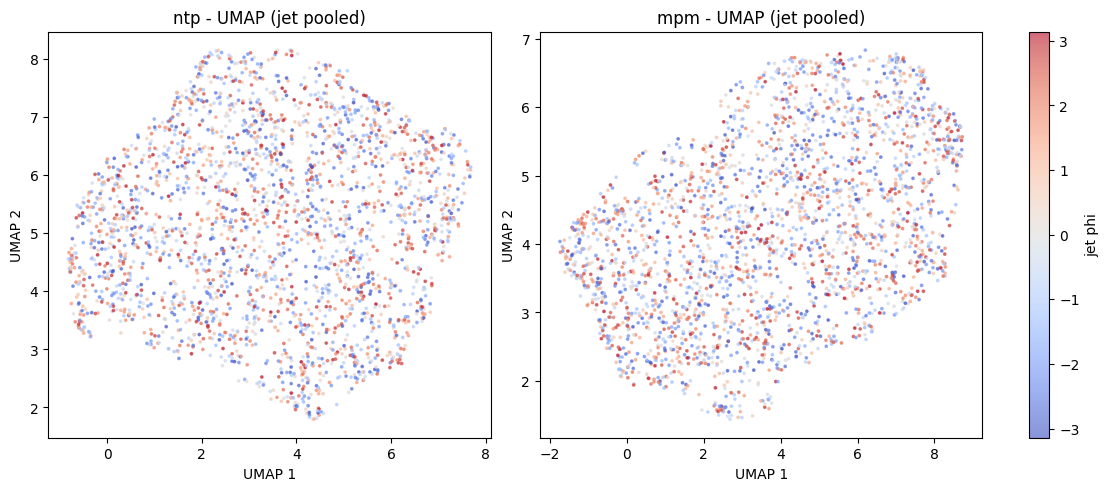

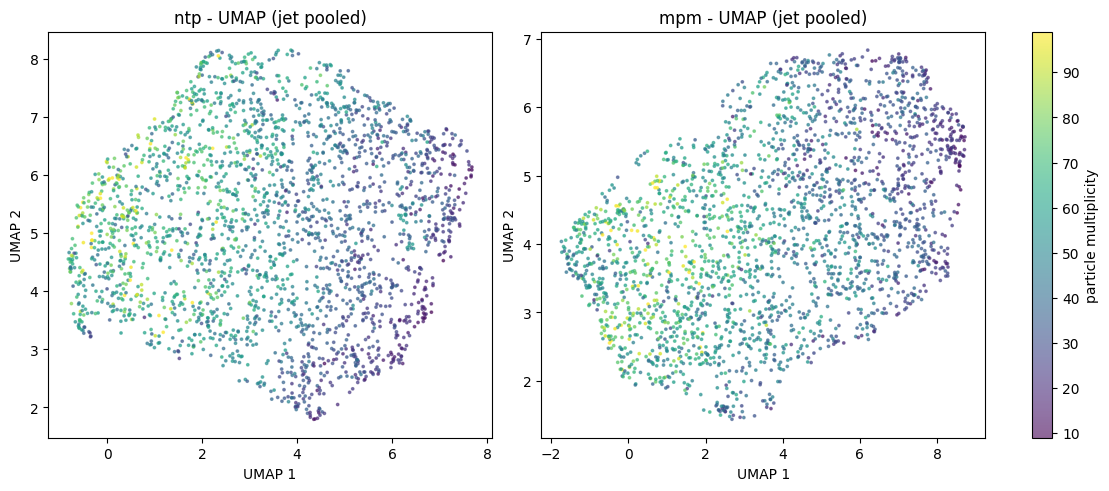

In [14]:
embeddings = embeddings_pooled["UMAP"]

for label, (values, cmap_kwargs, file_tag) in colorings.items():
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.8), layout="constrained")
    for ax, (name, emb) in zip(axs, embeddings.items()):
        sc = ax.scatter(emb[:, 0], emb[:, 1], c=values, s=3, alpha=0.6, **cmap_kwargs)
        ax.set_title(f"{name} - UMAP (jet pooled)")
        ax.set_xlabel("UMAP 1")
        ax.set_ylabel("UMAP 2")
    fig.colorbar(sc, ax=axs, label=label)
    fig.savefig(os.path.join(output_dir, f"ntp_vs_mpm_umap_jet_pooled_{file_tag}.png"), bbox_inches="tight")
    plt.show()


# tsne - jet pooled

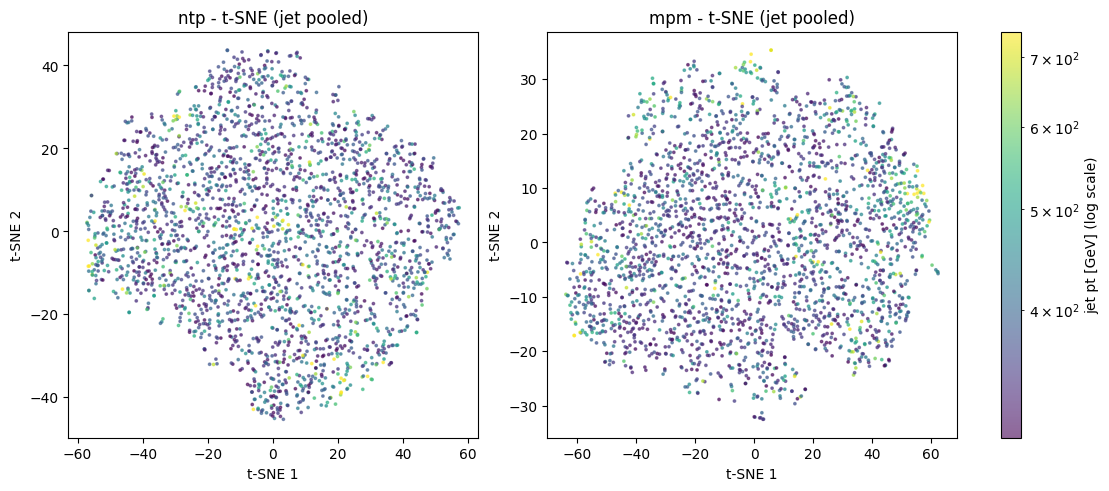

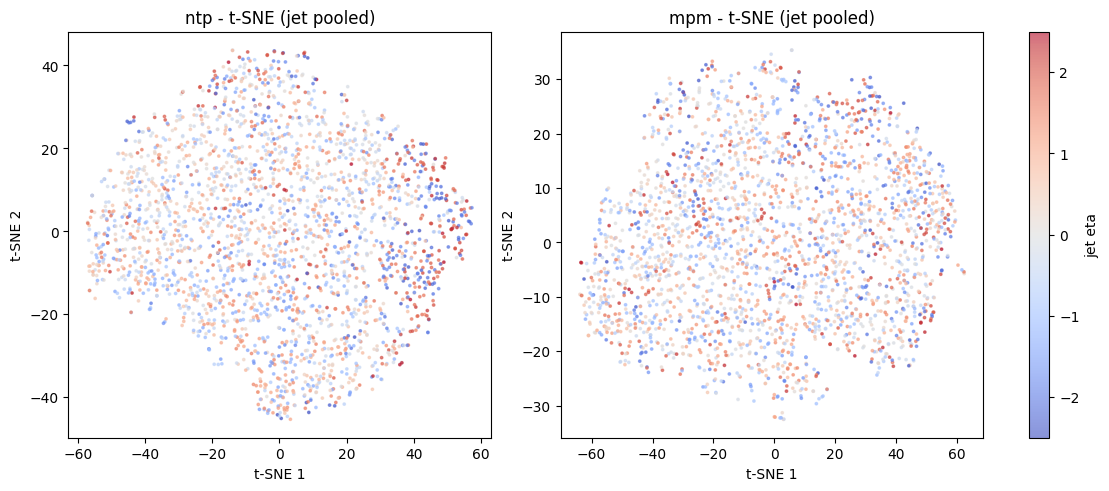

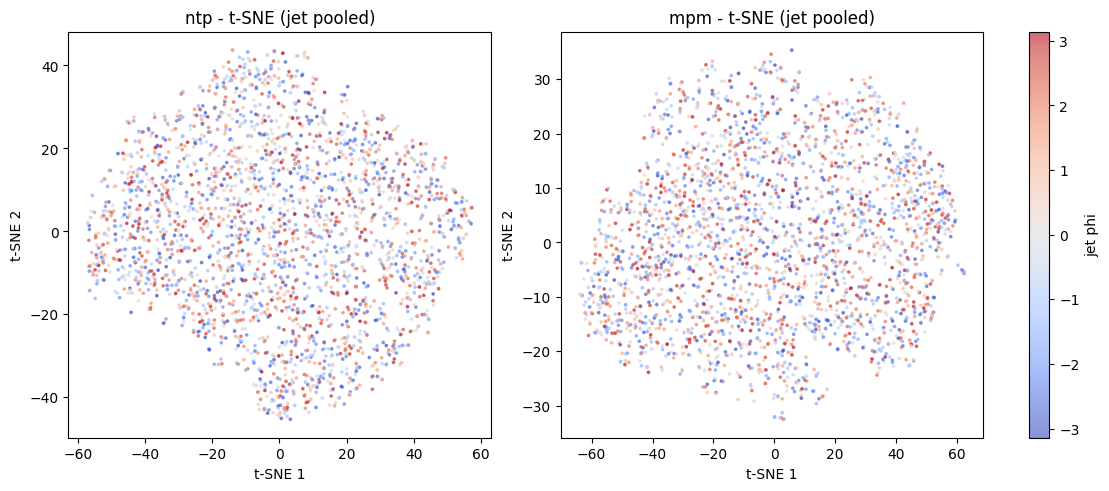

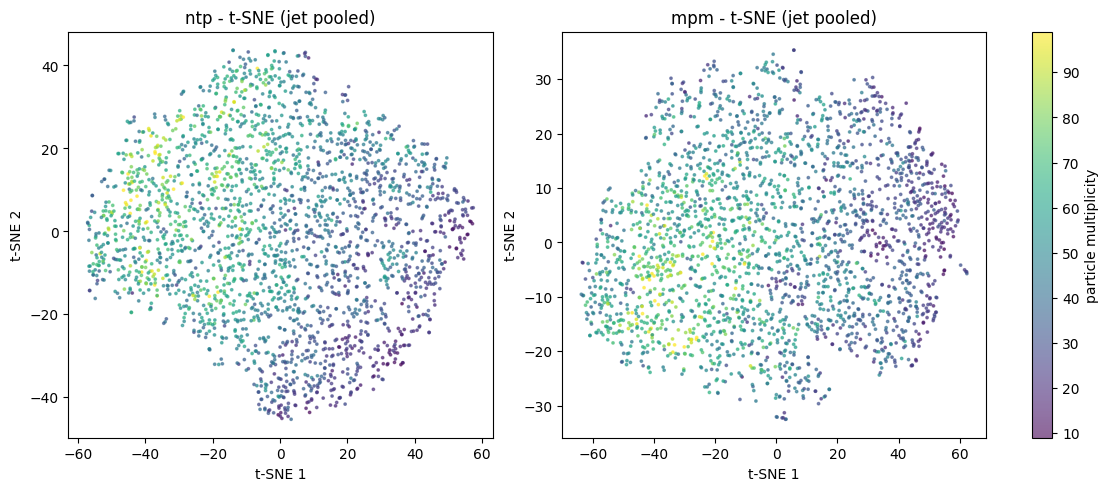

In [15]:
embeddings = embeddings_pooled["TSNE"]

for label, (values, cmap_kwargs, file_tag) in colorings.items():
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.8), layout="constrained")
    for ax, (name, emb) in zip(axs, embeddings.items()):
        sc = ax.scatter(emb[:, 0], emb[:, 1], c=values, s=3, alpha=0.6, **cmap_kwargs)
        ax.set_title(f"{name} - t-SNE (jet pooled)")
        ax.set_xlabel("t-SNE 1")
        ax.set_ylabel("t-SNE 2")
    fig.colorbar(sc, ax=axs, label=label)
    fig.savefig(os.path.join(output_dir, f"ntp_vs_mpm_tsne_jet_pooled_{file_tag}.png"), bbox_inches="tight")
    plt.show()


# constituent embedding

In [16]:
def flatten_backbone_out(backbone_out_list, mask_list):
    """One vector per jet made of all particles' latent reps (padded particles zeroed)."""
    flat = []
    for backbone_out, mask in zip(backbone_out_list, mask_list):
        flat.append((backbone_out * mask.unsqueeze(-1)).flatten(start_dim=1))
    return torch.cat(flat).numpy()


latents_flat = {
    "ntp": flatten_backbone_out(ntp_backbone_out_list, ntp_part_mask_list),
    "mpm": flatten_backbone_out(mpm_backbone_out_list, mpm_part_mask_list),
}
print({name: latent.shape for name, latent in latents_flat.items()})

# fit PCA once per model on the full (n_particles x latent_dim) vector of each jet
embeddings_flat = {
    "PCA": {name: PCA(n_components=2).fit_transform(latent) for name, latent in latents_flat.items()},
    "UMAP": {name: umap.UMAP(n_components=2, random_state=0).fit_transform(latent) for name, latent in latents_flat.items()},
    "TSNE": {name: TSNE(n_components=2, random_state=0).fit_transform(latent) for name, latent in latents_flat.items()},
}


{'ntp': (2500, 12800), 'mpm': (2500, 12800)}


/home/users/w/wozniak/.local/ntp4jets-umap/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/users/w/wozniak/.local/ntp4jets-umap/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


## PCA - constituent embedding

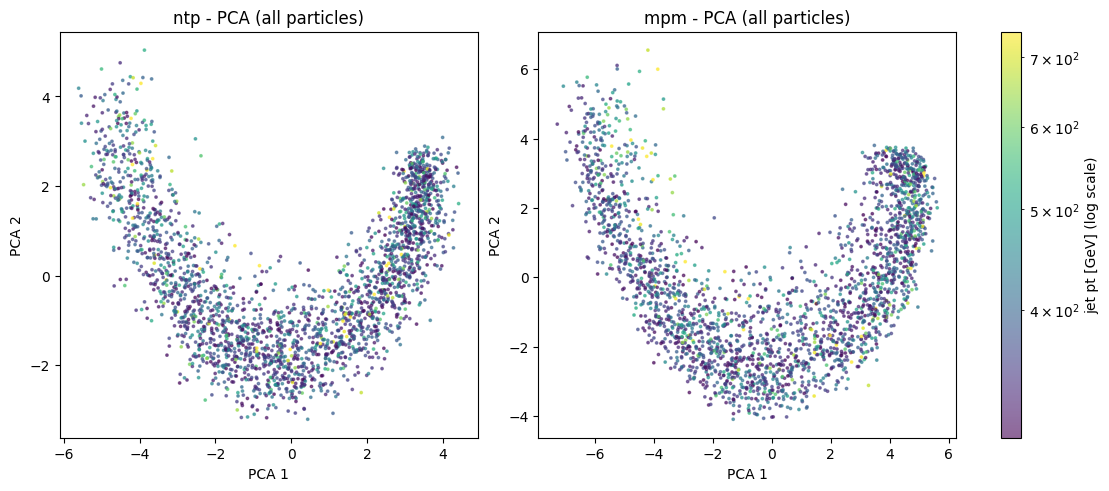

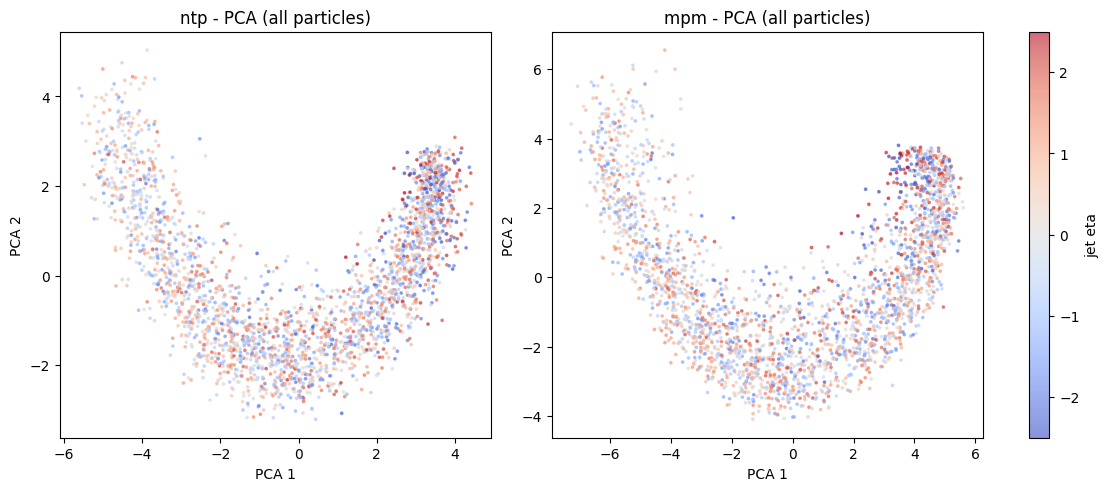

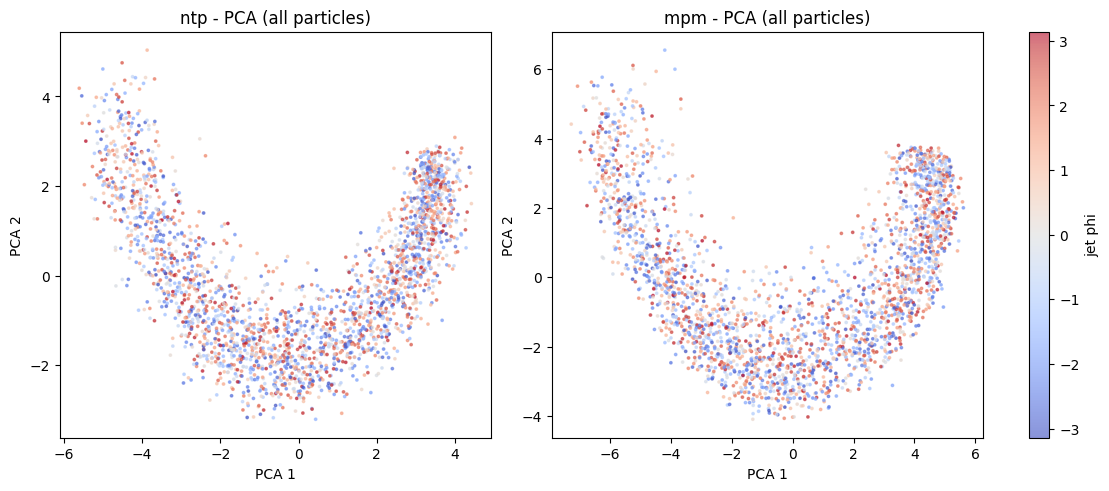

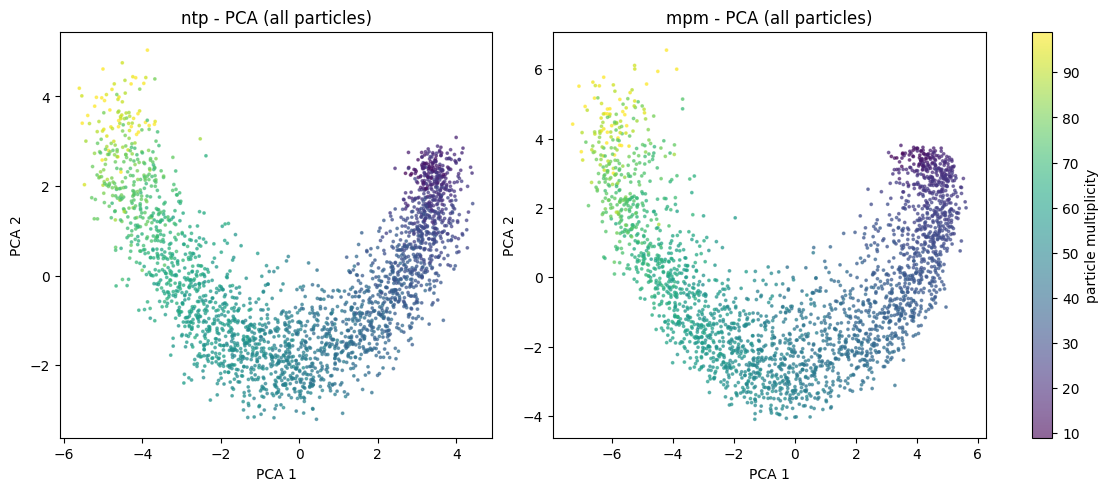

In [17]:
embeddings = embeddings_flat["PCA"]
for label, (values, cmap_kwargs, file_tag) in colorings.items():
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.8), layout="constrained")
    for ax, (name, emb) in zip(axs, embeddings.items()):
        sc = ax.scatter(emb[:, 0], emb[:, 1], c=values, s=3, alpha=0.6, **cmap_kwargs)
        ax.set_title(f"{name} - PCA (all particles)")
        ax.set_xlabel("PCA 1")
        ax.set_ylabel("PCA 2")
    fig.colorbar(sc, ax=axs, label=label)
    fig.savefig(
        os.path.join(output_dir, f"ntp_vs_mpm_backbone_pca_allparticles_{file_tag}.png"), bbox_inches="tight"
    )
    plt.show()


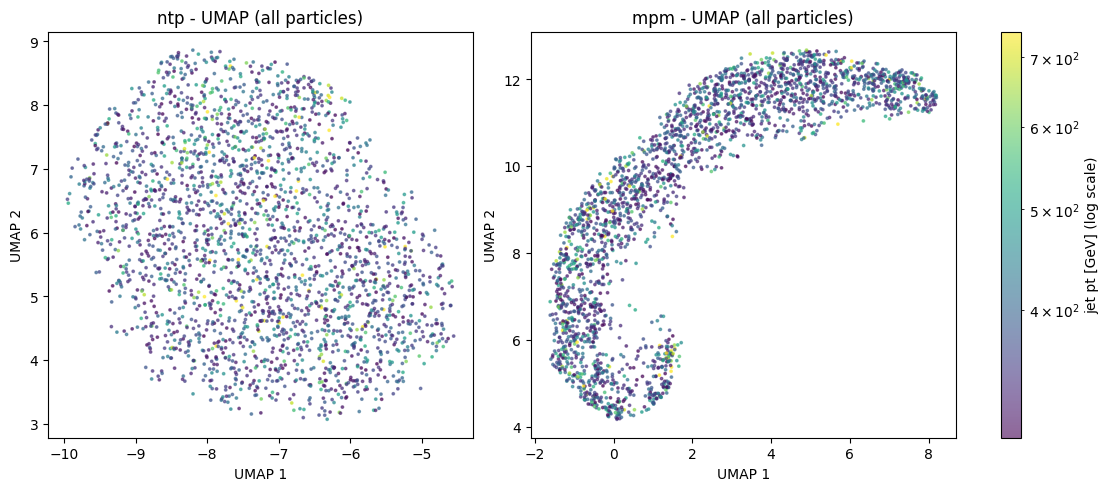

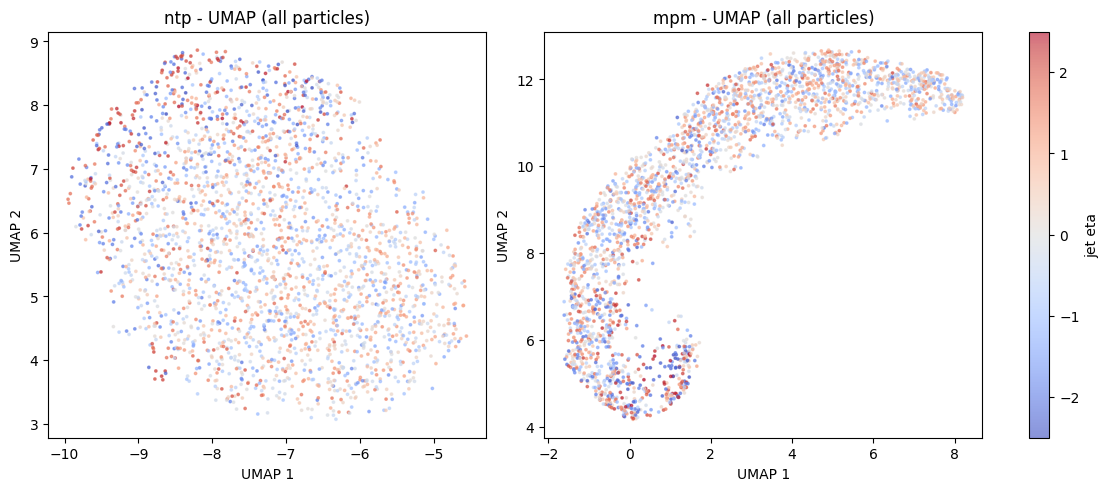

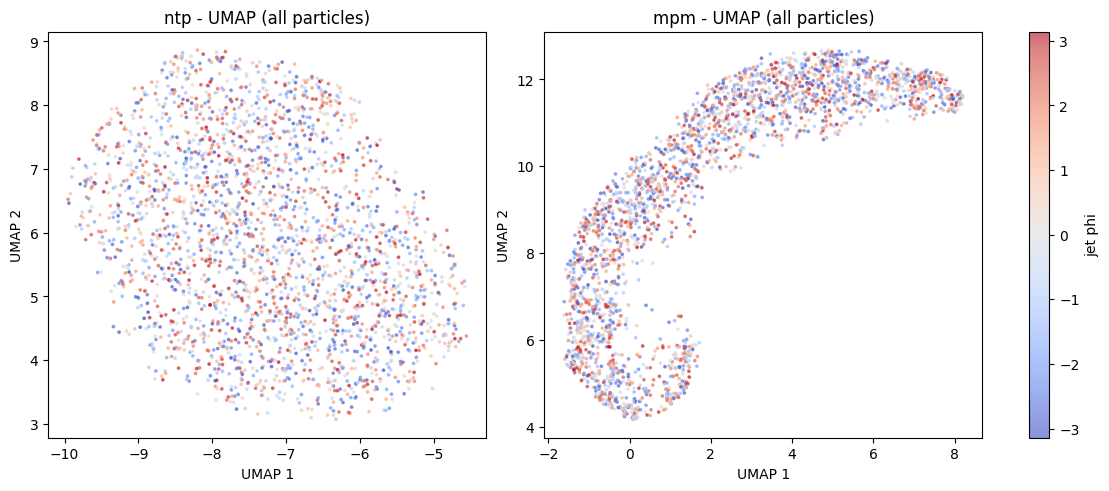

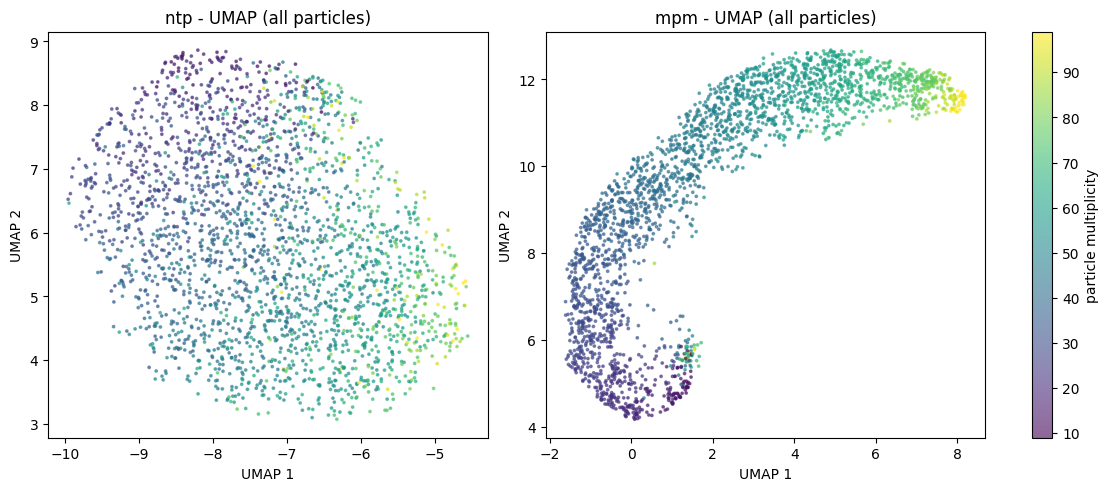

In [18]:
embeddings = embeddings_flat["UMAP"]

for label, (values, cmap_kwargs, file_tag) in colorings.items():
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.8), layout="constrained")
    for ax, (name, emb) in zip(axs, embeddings.items()):
        sc = ax.scatter(emb[:, 0], emb[:, 1], c=values, s=3, alpha=0.6, **cmap_kwargs)
        ax.set_title(f"{name} - UMAP (all particles)")
        ax.set_xlabel("UMAP 1")
        ax.set_ylabel("UMAP 2")
    fig.colorbar(sc, ax=axs, label=label)
    fig.savefig(os.path.join(output_dir, f"ntp_vs_mpm_umap_allparticles_{file_tag}.png"), bbox_inches="tight")
    plt.show()


## T-SNE constituent embedding

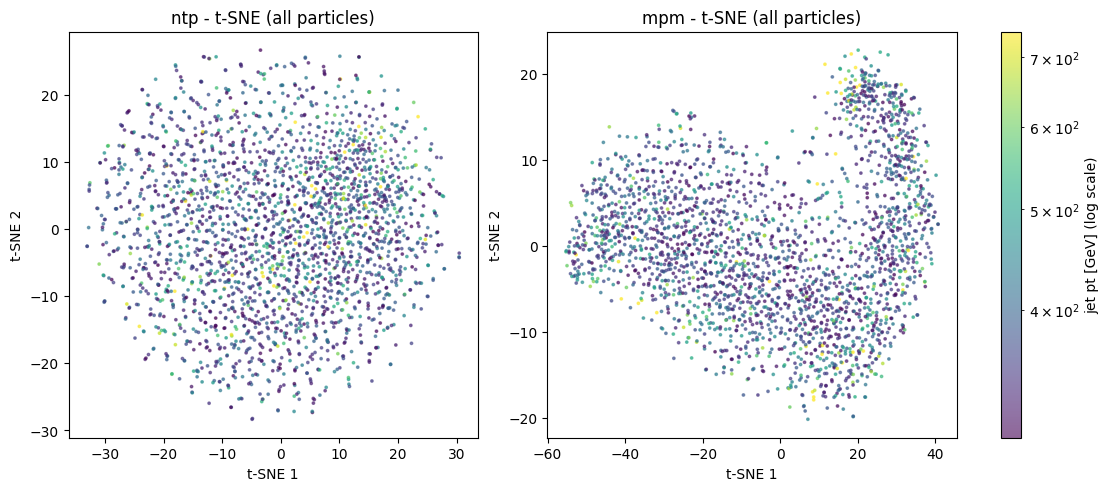

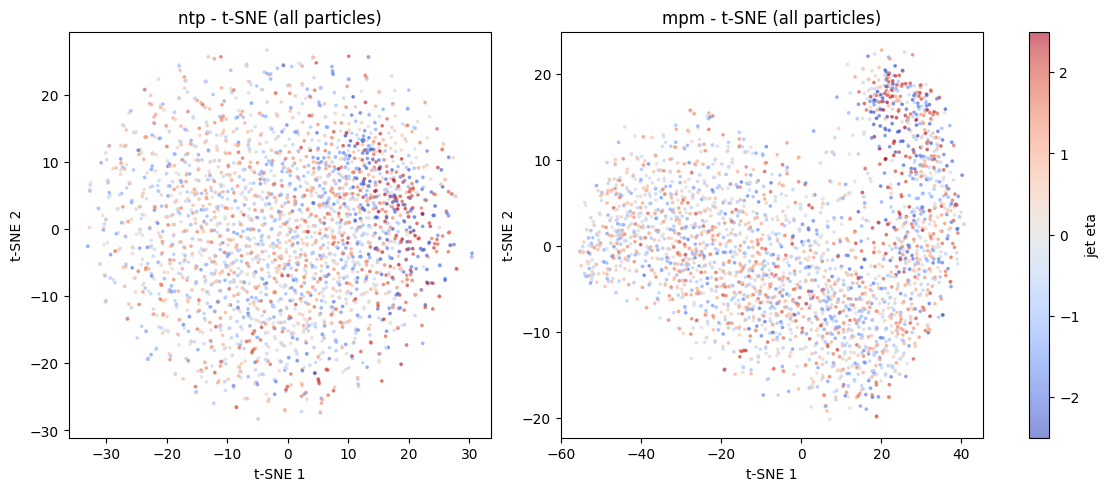

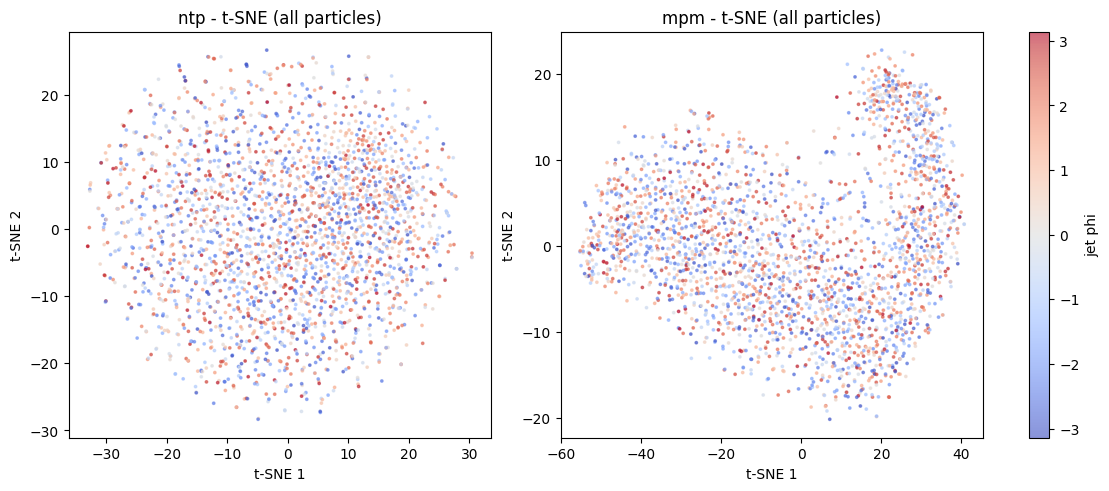

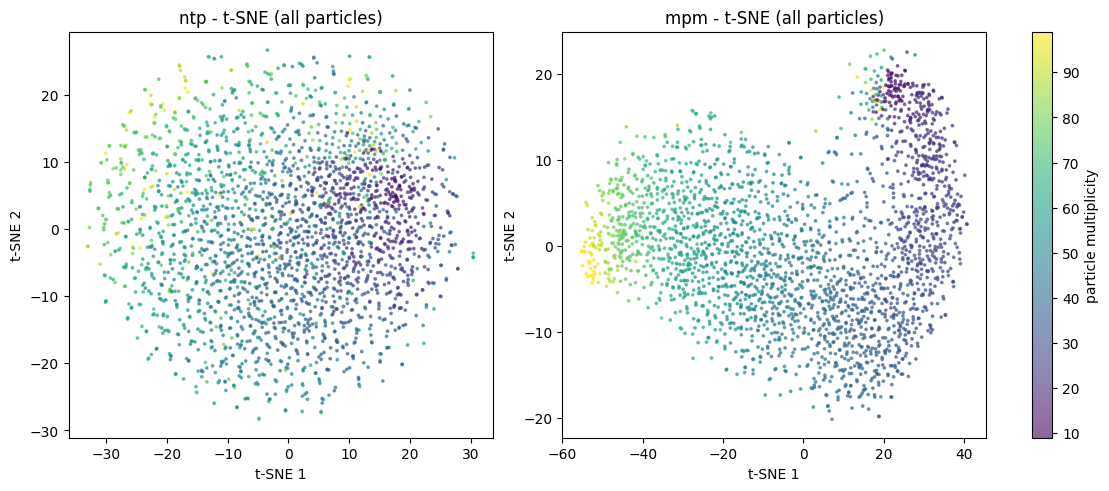

In [19]:

embeddings = embeddings_flat["TSNE"]

for label, (values, cmap_kwargs, file_tag) in colorings.items():
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.8), layout="constrained")
    for ax, (name, emb) in zip(axs, embeddings.items()):
        sc = ax.scatter(emb[:, 0], emb[:, 1], c=values, s=3, alpha=0.6, **cmap_kwargs)
        ax.set_title(f"{name} - t-SNE (all particles)")
        ax.set_xlabel("t-SNE 1")
        ax.set_ylabel("t-SNE 2")
    fig.colorbar(sc, ax=axs, label=label)
    fig.savefig(os.path.join(output_dir, f"ntp_vs_mpm_tsne_allparticles_{file_tag}.png"), bbox_inches="tight")
    plt.show()
